# Do Shared Lifestyle Habits Improve Roommate Ranking?
Lab 6 · Gehad Hamada and Zhumakan Zhanadil

**Question.** A student sees two possible roommates. Can we better predict which one they pick if we also know which habits they share?

**One example.** The student sleeps at 11 p.m. Candidate A sleeps at 11 p.m. and B sleeps at 1 a.m. The first model sees both candidates’ bedtimes. The second also sees that A’s bedtime is closer to the student’s.

**Algorithm.** We use logistic regression for both models. It learns from real survey choices: 1 means the student picked A, and 0 means they picked B. We judge the models by how often they agree with choices made by test students.

**Result.** General ranking agreed with 67.6% of test choices. Adding shared habits gave 64.9%. The extra information did not help on this test split.

Read **Steps 2, 4, 6, 7 and 9** first. The setup and helper cells are there so you can rerun the full lab.

**Run.** Use Python 3.9 with pandas 2.3.3, NumPy 1.26.4, scikit-learn 1.6.1 and Matplotlib 3.9.4. Place the [IRW v5.0 CSV](https://redivis.com/api/v1/tables/datapages.irw_conjoint:v5_0.shafranek_2021_roommate_choice/rows?format=csv) next to this notebook, or let the first cell download it. Run the cells in order. [Dataset and license](https://itemresponsewarehouse.org/tables/shafranek_2021_roommate_choice/) · [Original paper](https://doi.org/10.1007/s11109-019-09554-9).

The companion Word report explains the research sources, limitations and connection to InterNest.


## 1 Load and inspect the data

Read the CSV and count missing values and duplicates.

<details>
<summary>Lab methods and details</summary>

The CSV has one row per candidate shown. A survey question has two candidate rows. First read the file, then count rows, columns, missing values and repeated records.

</details>

In [1]:
from pathlib import Path
from hashlib import sha256
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder, StandardScaler

path = Path('shafranek_2021_roommate_choice.csv')
if not path.exists():
    url = ('https://redivis.com/api/v1/tables/datapages.irw_conjoint:v5_0.'
           'shafranek_2021_roommate_choice/rows?format=csv')
    urlretrieve(url, path)

expected_hash = '79ea9d09082bbb6c1b247ea8e535ce03e376da922ad79f36ab11651ba981bb27'
assert sha256(path.read_bytes()).hexdigest() == expected_hash
raw = pd.read_csv(path)

In [2]:
print('CSV dimensions:', raw.shape)
print('Respondents:', raw['id'].nunique())
print('Duplicate rows:', raw.duplicated().sum())
print('Duplicate survey keys:', raw.duplicated(['id', 'task', 'profile']).sum())
print('Total survey pairs:', raw.groupby(['id', 'task']).ngroups)

audit = pd.DataFrame({'Type': raw.dtypes, 'Missing': raw.isna().sum()})
with pd.option_context('display.max_rows', None):
    display(audit)

,Type,Missing
id,int64,0
task,int64,0
profile,int64,0
choice,float64,82
rating,float64,720
attr_race,object,0
attr_sexual_orientation,object,0
attr_religion,object,0
attr_party,object,0
attr_political_interest,object,0


CSV dimensions: (4036, 57)
Respondents: 203
Duplicate rows: 0
Duplicate survey keys: 0
Total survey pairs: 2018


## 2 Clean the data

Build one row per question. Keep a pair if the survey records exactly one winner. We keep 1,977 of 2,018 pairs.

<details>
<summary>Lab methods and details</summary>

**Before:** two rows per survey question. **After:** one pair with one answer. We keep a pair only if both choice values are present and exactly one candidate was chosen. This removes 41 of 2,018 pairs. The duplicate check found zero duplicate keys. A missing 1–7 rating is fine because this model predicts the choice.

</details>

In [3]:
candidate_fields = [
    'attr_cleanliness', 'attr_bedtime', 'attr_hobby', 'attr_music', 'attr_social'
]
student_fields = ['cov_own_hobbies', 'cov_own_music', 'cov_own_social', 'cov_own_bedtime']
pair_keys = ['id', 'task']

assert not raw.duplicated(pair_keys + ['profile']).any()
assert raw['profile'].isin([1, 2]).all()
assert raw['choice'].dropna().isin([0, 1]).all()
assert (raw.groupby(pair_keys).size() == 2).all()

paired = raw.pivot(index=pair_keys, columns='profile', values=candidate_fields + ['choice'])
profile_a = paired.xs(1, axis=1, level='profile').copy()
profile_b = paired.xs(2, axis=1, level='profile').copy()
valid = profile_a['choice'].notna() & profile_b['choice'].notna()
valid &= (profile_a['choice'] + profile_b['choice']) == 1
profile_a = profile_a.loc[valid]
profile_b = profile_b.loc[valid]

target = profile_a['choice'].astype(int)
student_ids = target.index.get_level_values('id')
print('Pairs excluded because a valid choice was unavailable:', (~valid).sum())
print('Usable choices:', len(target))
print('Rows with a missing lifestyle field:', raw[candidate_fields].isna().any(axis=1).sum())

Pairs excluded because a valid choice was unavailable: 41
Usable choices: 1977
Rows with a missing lifestyle field: 0


## 3 Split by student

Keep each student in just one set. This lets us test on students the model has never seen.

<details>
<summary>Lab methods and details</summary>

Training teaches the model, validation checks it during development, and test measures it on unseen students. Every choice from a given student stays in the same group. We do this before fitting the encoder, scaler or model.

</details>

In [4]:
first_split = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_rows, remaining_rows = next(first_split.split(target, groups=student_ids))
second_split = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_positions, test_positions = next(
    second_split.split(remaining_rows, groups=student_ids[remaining_rows])
)
validation_rows = remaining_rows[val_positions]
test_rows = remaining_rows[test_positions]

splits = {'Train': train_rows, 'Validation': validation_rows, 'Test': test_rows}
for name, rows in splits.items():
    print(name, '| Students:', student_ids[rows].nunique(), '| Pairs:', len(rows))
for first, second in [('Train', 'Validation'), ('Train', 'Test'), ('Validation', 'Test')]:
    assert set(student_ids[splits[first]]).isdisjoint(student_ids[splits[second]])

Train | Students: 142 | Pairs: 1388
Validation | Students: 30 | Pairs: 290
Test | Students: 31 | Pairs: 299


## 4 Explore the data

EDA means looking at the data before training. Read the class-balance plot first, then the cleanliness plot.

<details>
<summary>Lab methods and details</summary>

Analyze class balance and associations on training students. The raw audit above reports structural counts for the source file. Our predictors are lifestyle attributes plus four similarity comparisons. Politics, religion, race, sexual orientation and IDs stay outside the model.

</details>

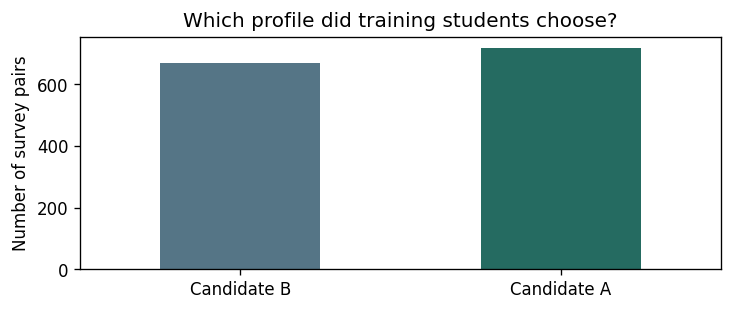

B: 670 | A: 718
Both choices are common. This plot checks whether one profile position dominates.


In [5]:
counts = target.iloc[train_rows].value_counts().reindex([0, 1])
counts.index = ['Candidate B', 'Candidate A']
counts.plot.bar(color=['#557586', '#256b61'], rot=0, figsize=(6.2, 2.7),
                title='Which profile did training students choose?')
plt.ylabel('Number of survey pairs')
plt.tight_layout()
plt.show()
print('B:', counts.iloc[0], '| A:', counts.iloc[1])
print('Both choices are common. This plot checks whether one profile position dominates.')

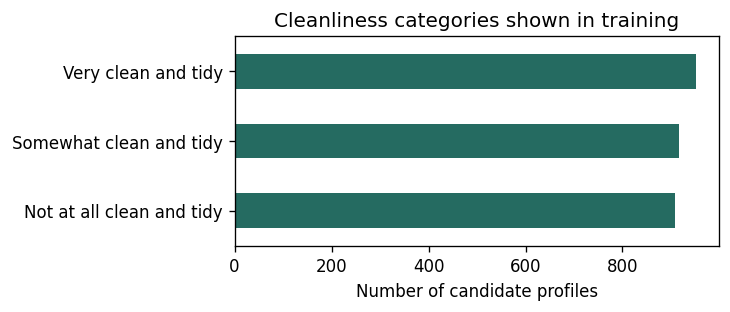

,Missing records
attr_cleanliness,0
attr_bedtime,0
attr_hobby,0
attr_music,0
attr_social,0
cov_own_hobbies,0
cov_own_music,40
cov_own_social,4
cov_own_bedtime,0


Counts: {'Not at all clean and tidy': 908, 'Somewhat clean and tidy': 917, 'Very clean and tidy': 951}
All three cleanliness levels have substantial training support.


In [6]:
training_profiles = pd.concat([profile_a.iloc[train_rows], profile_b.iloc[train_rows]])
cleanliness_counts = training_profiles['attr_cleanliness'].value_counts().sort_values()
cleanliness_counts.plot.barh(color='#256b61', figsize=(6.2, 2.7),
                             title='Cleanliness categories shown in training')
plt.xlabel('Number of candidate profiles')
plt.ylabel('')
plt.tight_layout()
plt.show()
print('Counts:', cleanliness_counts.to_dict())
print('All three cleanliness levels have substantial training support.')
audit_fields = raw[candidate_fields + student_fields].isna().sum()
display(audit_fields.to_frame('Missing records'))

## 5 Compare shared habits

Create four extra inputs: shared hobby, same music, same weekend habit and closer bedtime.

<details>
<summary>Lab methods and details</summary>

For each candidate, check shared hobby, same favorite music, same weekend habit and bedtime closeness. For example, the bedtime distance between 11 p.m. and 1 a.m. is two hours. We map midnight to 24, 1 a.m. to 25 and “2 a.m. or later” to 26 as an approximation. These are fixed survey coding rules. All distances remain within the valid survey categories. Missing respondent comparisons contribute a neutral zero difference.

</details>

In [7]:
# Verify that a student's own habits stay the same across their profile records.
for field in student_fields:
    assert (raw.groupby('id')[field].nunique(dropna=False) <= 1).all()

students = raw.drop_duplicates('id').set_index('id').loc[student_ids, student_fields].copy()
students.index = target.index

candidate_times = {'9 pm': 21, '11 pm': 23, '1 am': 25}
student_times = {
    '9:00 PM': 21, '10:00 PM': 22, '11:00 PM': 23,
    'Midnight': 24, '1:00 AM': 25, '2 am or later': 26,
}
weekend_words = {
    'Likes to stay in on weekends': 'I like to stay in on weekends.',
    'Likes to go to parties on weekends': 'I like to go to parties on weekends.',
}

**Calculate similarity for one candidate.** Each check asks whether that candidate has something in common with the searching student.

In [8]:
def similarity(profile):
    shared_hobby = []
    for candidate_hobby, own_hobbies in zip(profile['attr_hobby'], students['cov_own_hobbies']):
        if pd.isna(own_hobbies) or pd.isna(candidate_hobby):
            shared_hobby.append(np.nan)
        else:
            shared_hobby.append(float(candidate_hobby in own_hobbies.split(',')))

    same_music = (profile['attr_music'] == students['cov_own_music']).astype(float)
    same_music = same_music.where(profile['attr_music'].notna() & students['cov_own_music'].notna())
    candidate_weekend = profile['attr_social'].map(weekend_words)
    same_weekend = (candidate_weekend == students['cov_own_social']).astype(float)
    same_weekend = same_weekend.where(candidate_weekend.notna() & students['cov_own_social'].notna())
    bedtime_distance = (
        profile['attr_bedtime'].map(candidate_times) - students['cov_own_bedtime'].map(student_times)
    ).abs()

    return pd.DataFrame({
        'Shared hobby': shared_hobby,
        'Same music': same_music,
        'Same weekend habit': same_weekend,
        'Bedtime closeness': -bedtime_distance,
    }, index=target.index)

**Compare A with B.** If A shares a hobby and B does not, the difference is 1. If both share one, the difference is 0.

In [9]:
similarity_a = similarity(profile_a)
similarity_b = similarity(profile_b)
similarity_difference = (similarity_a - similarity_b).fillna(0)
print('Largest observed bedtime distance in training (hours):',
      -min(similarity_a.iloc[train_rows]['Bedtime closeness'].min(),
           similarity_b.iloc[train_rows]['Bedtime closeness'].min()))

Largest observed bedtime distance in training (hours): 5


## 6 Check correlation

Correlation asks whether a difference between A and B goes together with picking A. Cleanliness has the strongest association among candidate traits.

<details>
<summary>Lab methods and details</summary>

For a categorical level, calculate an A-minus-B indicator. “Very tidy” contributes +1 if it describes A only, −1 if it describes B only, and 0 if both or neither have it. A positive correlation means that when A has the feature advantage, students tended to pick A more often. Check the absolute value to compare which association is stronger. We report the strongest absolute association per candidate field and all four similarity associations. This is descriptive. It does not prove an effect or replace evaluation.

</details>

In [10]:
a_train = profile_a.iloc[train_rows]
b_train = profile_b.iloc[train_rows]
y_train = target.iloc[train_rows]
association_rows = []
for field in candidate_fields:
    categories = sorted(set(a_train[field].dropna()) | set(b_train[field].dropna()))
    for category in categories:
        difference = (a_train[field] == category).astype(int) - (b_train[field] == category).astype(int)
        association_rows.append({'Field': field, 'Category': category, 'Correlation': difference.corr(y_train)})

associations = pd.DataFrame(association_rows)
associations['Absolute correlation'] = associations['Correlation'].abs()
strongest = associations.sort_values('Absolute correlation', ascending=False).drop_duplicates('Field')
display(strongest.round(3))
personal_correlations = similarity_difference.iloc[train_rows].corrwith(y_train)
display(personal_correlations.round(3).to_frame('Correlation'))

,Field,Category,Correlation,Absolute correlation
0,attr_cleanliness,Not at all clean and tidy,-0.255,0.255
5,attr_bedtime,9 pm,-0.165,0.165
6,attr_hobby,Cars & auto mechanics,-0.078,0.078
17,attr_music,Country music,-0.073,0.073
22,attr_social,Likes to stay in on weekends,-0.060,0.060


,Correlation
Shared hobby,0.052
Same music,0.062
Same weekend habit,0.144
Bedtime closeness,0.225


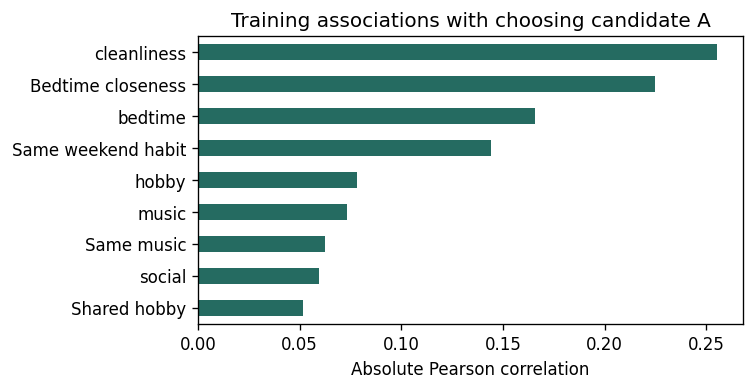

Strongest candidate field: attr_cleanliness
A high correlation for a single feature is a clue. The grouped validation compares the complete models.


In [11]:
plot_scores = strongest.set_index('Field')['Correlation'].abs()
plot_scores.index = plot_scores.index.str.replace('attr_', '', regex=False)
plot_scores = pd.concat([plot_scores, personal_correlations.abs()]).sort_values()
plot_scores.plot.barh(color='#256b61', figsize=(6.4, 3.35), title='Training associations with choosing candidate A')
plt.xlabel('Absolute Pearson correlation')
plt.tight_layout()
plt.show()
print('Strongest candidate field:', strongest.iloc[0]['Field'])
print('A high correlation for a single feature is a clue. The grouped validation compares the complete models.')

## 7 Train logistic regression

Convert categories into yes/no columns, compare A and B, and train logistic regression. We compare both input sets with a 50% guessing baseline.

<details>
<summary>Lab methods and details</summary>

The baseline gives both candidates an equal chance, so its expected agreement is 50%. The general model compares the five lifestyle traits. The second model adds four similarity differences. Both use the same logistic regression with no intercept. If we swap A and B, the score changes sign. A zero score gives a tie.

The encoder learns categories from training profiles only. Missing candidate fields use an explicit category. We keep the binary indicators at their natural scale and rescale the bedtime difference using the training standard deviation. We do not subtract the mean, so swapping A and B still reverses the score. Both fitted models use the same fixed regularization. The structured categories have no outliers that require removal.

</details>

**Prepare the model inputs.** Convert each category to yes/no columns, then subtract B’s columns from A’s.

In [12]:
def make_inputs(fit_rows, evaluation_rows, include_similarity):
    train_a = profile_a.iloc[fit_rows][candidate_fields].fillna('Missing').astype(str)
    train_b = profile_b.iloc[fit_rows][candidate_fields].fillna('Missing').astype(str)
    check_a = profile_a.iloc[evaluation_rows][candidate_fields].fillna('Missing').astype(str)
    check_b = profile_b.iloc[evaluation_rows][candidate_fields].fillna('Missing').astype(str)

    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    encoder.fit(pd.concat([train_a, train_b]))
    x_train = encoder.transform(train_a) - encoder.transform(train_b)
    x_check = encoder.transform(check_a) - encoder.transform(check_b)
    if include_similarity:
        train_similarity = similarity_difference.iloc[fit_rows].copy()
        check_similarity = similarity_difference.iloc[evaluation_rows].copy()
        bedtime_column = ['Bedtime closeness']
        scaler = StandardScaler(with_mean=False)
        train_similarity[bedtime_column] = scaler.fit_transform(train_similarity[bedtime_column])
        check_similarity[bedtime_column] = scaler.transform(check_similarity[bedtime_column])
        x_train = np.column_stack([x_train, train_similarity])
        x_check = np.column_stack([x_check, check_similarity])
    return x_train, x_check

**This is the algorithm.** `LogisticRegression(...)` creates the model. `fit(...)` learns from survey choices. `predict_proba(...)` gives the estimated probability of choosing A.

In [13]:
def predict_choices(fit_rows, evaluation_rows, include_similarity):
    x_train, x_check = make_inputs(fit_rows, evaluation_rows, include_similarity)
    model = LogisticRegression(fit_intercept=False, C=1, max_iter=1000)
    model.fit(x_train, target.iloc[fit_rows])
    return model.predict_proba(x_check)[:, 1]

**How we grade the model.** Agreement checks whether the predicted winner is the candidate the student picked. A tie counts as half right.

In [14]:
def agreement(labels, probabilities):
    correct = (probabilities > 0.5) == np.asarray(labels)
    return np.where(np.isclose(probabilities, 0.5), 0.5, correct).mean()

def compare_models(label, rows):
    y = target.iloc[rows]
    results = []
    for name in ['Random baseline', 'General ranking', 'Similarity ranking']:
        if name == 'Random baseline':
            probabilities = np.full(len(rows), 0.5)
        else:
            probabilities = predict_choices(train_rows, rows, name == 'Similarity ranking')
        results.append({
            'Split': label, 'Model': name, 'Agreement': agreement(y, probabilities),
            'ROC AUC': roc_auc_score(y, probabilities), 'Log loss': log_loss(y, probabilities),
        })
    return results

In [15]:
validation_results = compare_models('Validation', validation_rows)
print('Validation comparison')
display(pd.DataFrame(validation_results).round(4))

,Split,Model,Agreement,ROC AUC,Log loss
0,Validation,Random baseline,0.5000,0.5000,0.6931
1,Validation,General ranking,0.6707,0.7298,0.6131
2,Validation,Similarity ranking,0.6914,0.7418,0.6003


Validation comparison


## 8 Read the learning curves

Train with more students at each step and check the same validation group.

<details>
<summary>Lab methods and details</summary>

Train on increasing numbers of students and score the same validation students at every step. All input encoding is fitted again inside each smaller fit. The test group stays out of the curves.

</details>

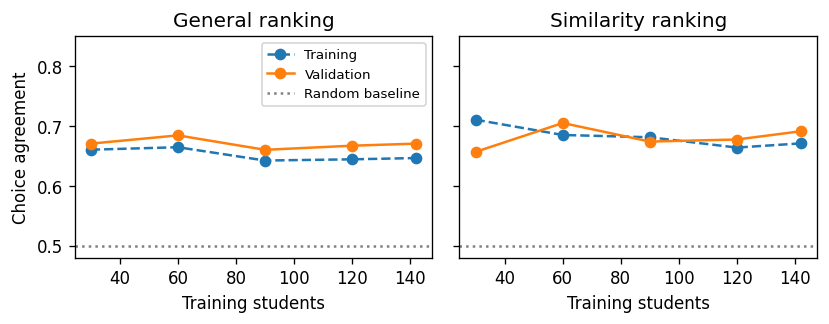

General ranking | full train: 0.647 | validation: 0.671
Similarity ranking | full train: 0.671 | validation: 0.691
Both validation curves stay above chance. A training–validation gap can reflect overfitting or differences between groups.


In [16]:
training_students = pd.Series(student_ids[train_rows].unique()).sample(frac=1, random_state=42)
sizes = [30, 60, 90, 120, len(training_students)]
figure, axes = plt.subplots(1, 2, figsize=(7, 2.8), sharey=True)

for axis, title, include_similarity in zip(
    axes, ['General ranking', 'Similarity ranking'], [False, True]
):
    training_scores = []
    validation_scores = []
    for size in sizes:
        included_students = training_students.iloc[:size]
        subset = train_rows[student_ids[train_rows].isin(included_students)]
        training_predictions = predict_choices(subset, subset, include_similarity)
        validation_predictions = predict_choices(subset, validation_rows, include_similarity)
        training_scores.append(agreement(target.iloc[subset], training_predictions))
        validation_scores.append(agreement(target.iloc[validation_rows], validation_predictions))
    axis.plot(sizes, training_scores, 'o--', label='Training')
    axis.plot(sizes, validation_scores, 'o-', label='Validation')
    axis.axhline(0.5, color='gray', linestyle=':', label='Random baseline')
    axis.set(title=title, xlabel='Training students', ylim=(0.48, 0.85))
    print(title, '| full train:', round(training_scores[-1], 3),
          '| validation:', round(validation_scores[-1], 3))

axes[0].set_ylabel('Choice agreement')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
print('Both validation curves stay above chance. A training–validation gap can reflect overfitting or differences between groups.')

## 9 Check the final results

Check both models on the same test students. Choice agreement is the main score. AUC and log loss are supporting metrics.

<details>
<summary>Lab methods and details</summary>

Agreement is the fraction of choices the model gets right, with half credit for ties. ROC AUC measures how well the scores separate A choices from B choices. Log loss penalizes confident wrong predictions. The comparison uses the same test respondents for both models. This survey and split have been explored in earlier prototypes, so a new local sample is needed for confirmation.

</details>

In [17]:
test_results = compare_models('Test', test_rows)
results = pd.DataFrame(validation_results + test_results)
display(results.round(4))

general = test_results[1]['Agreement']
similarity_model = test_results[2]['Agreement']
print(f'Test change after adding similarity: {(similarity_model - general)*100:+.2f} percentage points')

,Split,Model,Agreement,ROC AUC,Log loss
0,Validation,Random baseline,0.5000,0.5000,0.6931
1,Validation,General ranking,0.6707,0.7298,0.6131
2,Validation,Similarity ranking,0.6914,0.7418,0.6003
3,Test,Random baseline,0.5000,0.5000,0.6931
4,Test,General ranking,0.6756,0.7056,0.6273
5,Test,Similarity ranking,0.6488,0.7104,0.6286


Test change after adding similarity: -2.68 percentage points


**InterNest decision.** Matching on how similar two people are may miss what each person wants. The survey also asked for a forced choice and did not measure whether roommates actually got along. InterNest can filter candidates by mutual dealbreakers, then compare stated preferences with candidates' actual habits in both directions. Consent-based local relevance judgments are needed to validate a personalized ranker.